# Xấp xỉ hàm Gaussian bằng MLP — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/1. MLP/Func_apxm_MLP.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| `Input(shape=(2,))` + `Dense(B, 'sigmoid')` + `Dense(1, 'sigmoid')` | `nn.Sequential(nn.Linear(2,B), nn.Sigmoid(), nn.Linear(B,1), nn.Sigmoid())` |
| `model.compile(loss='mean_squared_error', optimizer=SGD(lr=0.01))` | `nn.MSELoss()`, `torch.optim.SGD(lr=0.01)` |
| `model.fit(..., batch_size=128, epochs=C, verbose=0)` | vòng lặp `for epoch` tự viết + `DataLoader(batch_size=128, shuffle=True)` |
| `model.evaluate(x, y)` | hàm `evaluate()`: `model.eval()` + `torch.no_grad()` → MSE |

# (1) import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

from scipy.stats import multivariate_normal

np.random.seed(2024); torch.manual_seed(2024)

ROOT = d:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


# (2) data preparation

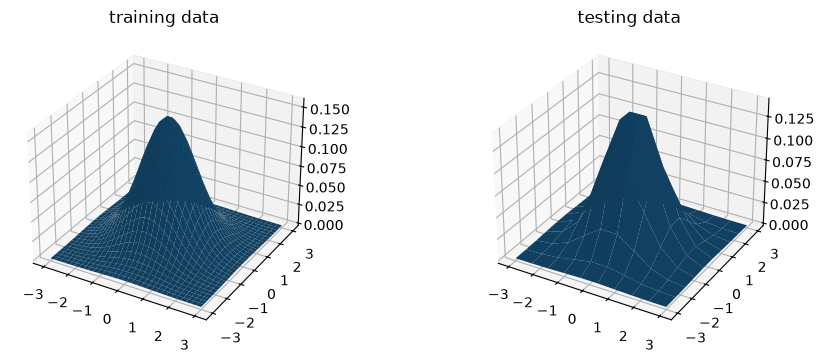

x_train (1024, 2) | x_test (100, 2)


In [2]:
# training ------------------------------  (lưới 32x32 = 1024 điểm, giống bản gốc)
A = 32j
x1, x2 = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2 = np.column_stack([x1.flat, x2.flat])
mu = np.array([0.0, 0.0])
covariance = np.diag([1, 1])
y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance).reshape(x1.shape)
x_train, y_train = x1x2.astype(np.float32), y.flatten().astype(np.float32)

fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121, projection="3d"); ax.plot_surface(x1, x2, y); ax.set_title("training data")

# testing -------------------------------  (lưới 10x10 = 100 điểm)
A = 10j
x1, x2 = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2 = np.column_stack([x1.flat, x2.flat])
y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance).reshape(x1.shape)
x_test, y_test = x1x2.astype(np.float32), y.flatten().astype(np.float32)
ax = fig.add_subplot(122, projection="3d"); ax.plot_surface(x1, x2, y); ax.set_title("testing data")
plt.show()
print("x_train", x_train.shape, "| x_test", x_test.shape)

# (3) MLP

In [3]:
def keras_init(model):
    """Khởi tạo giống mặc định Keras: kernel glorot_uniform, bias = 0
    (PyTorch mặc định dùng kaiming_uniform nên kết quả có thể lệch nhẹ nếu không làm bước này)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)
    return model


def gauss_mlp(B=16):
    """Keras: Input(2) -> Dense(B, sigmoid, name='fc') -> Dense(1, sigmoid, name='gauss_apxm')"""
    model = nn.Sequential()
    model.add_module("fc", nn.Linear(2, B))
    model.add_module("fc_act", nn.Sigmoid())
    model.add_module("gauss_apxm", nn.Linear(B, 1))
    model.add_module("out_act", nn.Sigmoid())
    return keras_init(model).to(DEVICE)


print(gauss_mlp(16))

Sequential(
  (fc): Linear(in_features=2, out_features=16, bias=True)
  (fc_act): Sigmoid()
  (gauss_apxm): Linear(in_features=16, out_features=1, bias=True)
  (out_act): Sigmoid()
)


# (4) training and evaluating MLP

In [4]:
X_TRAIN_T = torch.from_numpy(x_train); Y_TRAIN_T = torch.from_numpy(y_train).unsqueeze(1)   # y: (N,) -> (N,1)
X_TEST_T = torch.from_numpy(x_test); Y_TEST_T = torch.from_numpy(y_test).unsqueeze(1)
loss_fn = nn.MSELoss()


def evaluate(model, x, y):
    """Tương đương model.evaluate(x, y, verbose=0) -> MSE"""
    model.eval()
    with torch.no_grad():
        return loss_fn(model(x.to(DEVICE)), y.to(DEVICE)).item()


def train_gauss(A, B, C, lr=0.01, batch_size=128, tot_train=1001):
    """Một lần chạy: tạo model, chọn A mẫu, train C epoch bằng SGD, trả về (train MSE, test MSE)."""
    model = gauss_mlp(B=B)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    # items for training (giống bản gốc: chọn A chỉ số trong range(1, tot_train), không lặp)
    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)
    loader = DataLoader(TensorDataset(X_TRAIN_T[sel_indx], Y_TRAIN_T[sel_indx]), batch_size=batch_size, shuffle=True)
    for epoch in range(C):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return evaluate(model, X_TRAIN_T, Y_TRAIN_T), evaluate(model, X_TEST_T, Y_TEST_T)


def plot_curve(xs, tr, te, title, xlabel):
    plt.plot(xs, tr, marker="o", label="training"); plt.plot(xs, te, marker="o", label="testing")
    plt.legend(); plt.title(title); plt.xlabel(xlabel); plt.ylabel("Error (MSE)"); plt.grid(alpha=.3); plt.show()

### (4.1) Number of training samples (A) (no. of hidden nodes (B) = 16 and no. of epochs (C) = 100)

A =  100: train MSE = 5.216e-02, test MSE = 5.416e-02


A =  200: train MSE = 7.652e-02, test MSE = 7.946e-02


A =  300: train MSE = 2.435e-02, test MSE = 2.560e-02


A =  400: train MSE = 2.415e-02, test MSE = 2.534e-02


A =  500: train MSE = 1.618e-02, test MSE = 1.696e-02


A =  600: train MSE = 1.388e-02, test MSE = 1.476e-02


A =  700: train MSE = 1.265e-02, test MSE = 1.337e-02


A =  800: train MSE = 9.226e-03, test MSE = 9.794e-03


A =  900: train MSE = 7.260e-03, test MSE = 7.785e-03


A = 1000: train MSE = 7.757e-03, test MSE = 8.250e-03


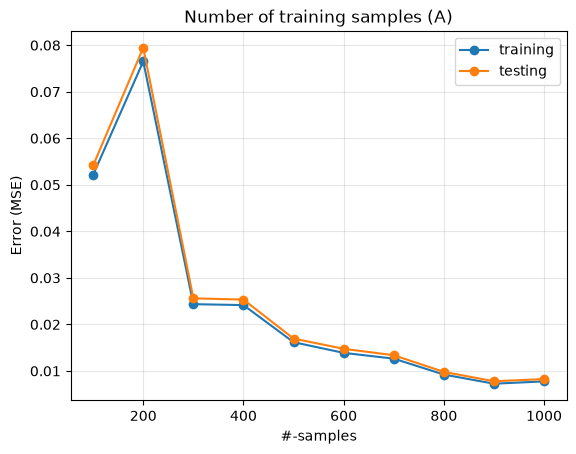

In [5]:
train_error, test_error, A_array = [], [], []
B, C = 16, 100
for A in np.arange(100, 1001, 100):
    tr, te = train_gauss(A=A, B=B, C=C)
    train_error.append(tr); test_error.append(te); A_array.append(A)
    print(f"A = {A:4d}: train MSE = {tr:.3e}, test MSE = {te:.3e}")
plot_curve(A_array, train_error, test_error, "Number of training samples (A)", "#-samples")

### (4.2) Number of hidden nodes (B) (no. of training samples (A) = 800 and no. of epochs (C) = 100)

B =    8: train MSE = 1.576e-02, test MSE = 1.691e-02


B =   16: train MSE = 1.209e-02, test MSE = 1.322e-02


B =   32: train MSE = 4.815e-03, test MSE = 5.141e-03


B =   64: train MSE = 2.726e-03, test MSE = 2.897e-03


B =  128: train MSE = 1.798e-03, test MSE = 1.836e-03


B =  256: train MSE = 1.510e-03, test MSE = 1.479e-03


B =  512: train MSE = 1.423e-03, test MSE = 1.353e-03


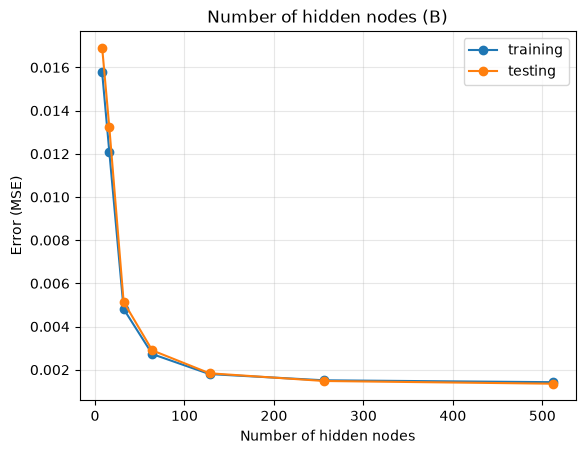

In [6]:
train_error, test_error, B_array = [], [], []
A, B, C = 800, 8, 100
while B <= 512:
    tr, te = train_gauss(A=A, B=B, C=C)
    train_error.append(tr); test_error.append(te); B_array.append(B)
    print(f"B = {B:4d}: train MSE = {tr:.3e}, test MSE = {te:.3e}")
    B *= 2
plot_curve(B_array, train_error, test_error, "Number of hidden nodes (B)", "Number of hidden nodes")

### (4.3) Number of epochs (C) (no. of training samples (A) = 800 and no. of hidden nodes (B) = 128)

C =   10: train MSE = 1.362e-02, test MSE = 1.430e-02
C =   20: train MSE = 6.573e-03, test MSE = 6.979e-03


C =   30: train MSE = 4.041e-03, test MSE = 4.307e-03


C =   40: train MSE = 3.225e-03, test MSE = 3.426e-03


C =   50: train MSE = 2.701e-03, test MSE = 2.854e-03


C =   60: train MSE = 2.424e-03, test MSE = 2.549e-03


C =   70: train MSE = 2.249e-03, test MSE = 2.354e-03


... (8 outputs left out)

C =  160: train MSE = 1.579e-03, test MSE = 1.568e-03


C =  170: train MSE = 1.580e-03, test MSE = 1.569e-03


C =  180: train MSE = 1.530e-03, test MSE = 1.506e-03


C =  190: train MSE = 1.536e-03, test MSE = 1.510e-03


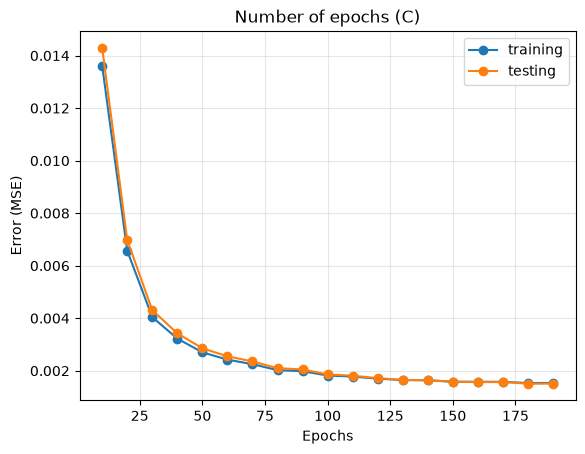

In [7]:
train_error, test_error, C_array = [], [], []
A, B = 800, 128
for C in np.arange(10, 200, 10):
    tr, te = train_gauss(A=A, B=B, C=C)
    train_error.append(tr); test_error.append(te); C_array.append(C)
    print(f"C = {C:4d}: train MSE = {tr:.3e}, test MSE = {te:.3e}")
plot_curve(C_array, train_error, test_error, "Number of epochs (C)", "Epochs")

**Nhận xét (theo kết quả đã chạy):** sai số giảm rõ khi tăng cả ba đại lượng.
- Tăng số mẫu A từ 100 → 1000: test MSE giảm từ khoảng 0.054 xuống 0.008 (A càng lớn, mỗi epoch càng nhiều bước cập nhật).
- Tăng số nơ-ron B từ 8 → 512: test MSE giảm từ khoảng 0.017 xuống 0.0014 (mạng rộng hơn biểu diễn tốt hơn).
- Tăng số epoch C từ 10 → 190: test MSE giảm từ khoảng 0.014 xuống 0.0015, sau khoảng 150 epoch gần như không giảm nữa.

Train MSE và test MSE luôn gần nhau, tức là mô hình không bị overfitting.